# CarDD — шесть классов повреждений

Данные: `datasets/cardd/`. Файлы `train.json`, `val.json`, `test.json` содержат COCO-полигоны и рамки; фото лежат в одноимённых папках.

Классы: `dent`, `scratch`, `crack`, `glass shatter`, `lamp broken`, `tire flat`. `SPLIT`: `train`, `val`, `test`, `all`. Пример: `CLASS_FILTER = "dent"`. Фильтр выбирает фото с этим классом; на выбранном фото показываются все аннотации.

Запустите ячейки сверху вниз. **Для новой случайной подборки повторите последнюю ячейку.** Настройки: количество фото, выборка, фильтр класса, случайное зерно, контуры, рамки и подписи. Исходные поля выбранной записи: `selected_samples[0]["metadata"]`.


In [1]:
import csv
import json
import sys
from pathlib import Path

current_dir = Path.cwd().resolve()
PROJECT_ROOT = next(
    (path for path in [current_dir, *current_dir.parents] if (path / "datasets").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Откройте ноутбук из папки проекта с каталогом datasets/.")
VIEWERS_DIR = PROJECT_ROOT / "code" / "viewers"
if str(VIEWERS_DIR) not in sys.path:
    sys.path.insert(0, str(VIEWERS_DIR))

from viewer_common import (
    IMAGE_SUFFIXES, image_files, load_coco, load_supervisely,
    read_jsonl, show_samples, summarize,
)


In [2]:
DATASET_ROOT = PROJECT_ROOT / "datasets" / "cardd"
SPLIT = "train"
N_IMAGES = 6
N_COLS = 3
SEED = None                 # Целое число фиксирует подборку
CLASS_FILTER = None         # Название класса или список; None = все
SHOW_MASKS = True
SHOW_BOXES = True
SHOW_LABELS = True
SHOW_CLASS_IDS = False
ONLY_ANNOTATED = False


In [3]:
dataset = []
for split_name in ("train", "val", "test"):
    dataset.extend(load_coco(
        DATASET_ROOT / f"{split_name}.json",
        DATASET_ROOT / split_name,
        split_name,
    ))
summary = summarize(dataset)


Записей: 4,000; изображения отсутствуют: 0
Выборки: {'train': 2816, 'val': 810, 'test': 374}
Классы (число меток):
  crack: 898
  dent: 2,543
  glass shatter: 681
  lamp broken: 704
  scratch: 3,595
  tire flat: 319


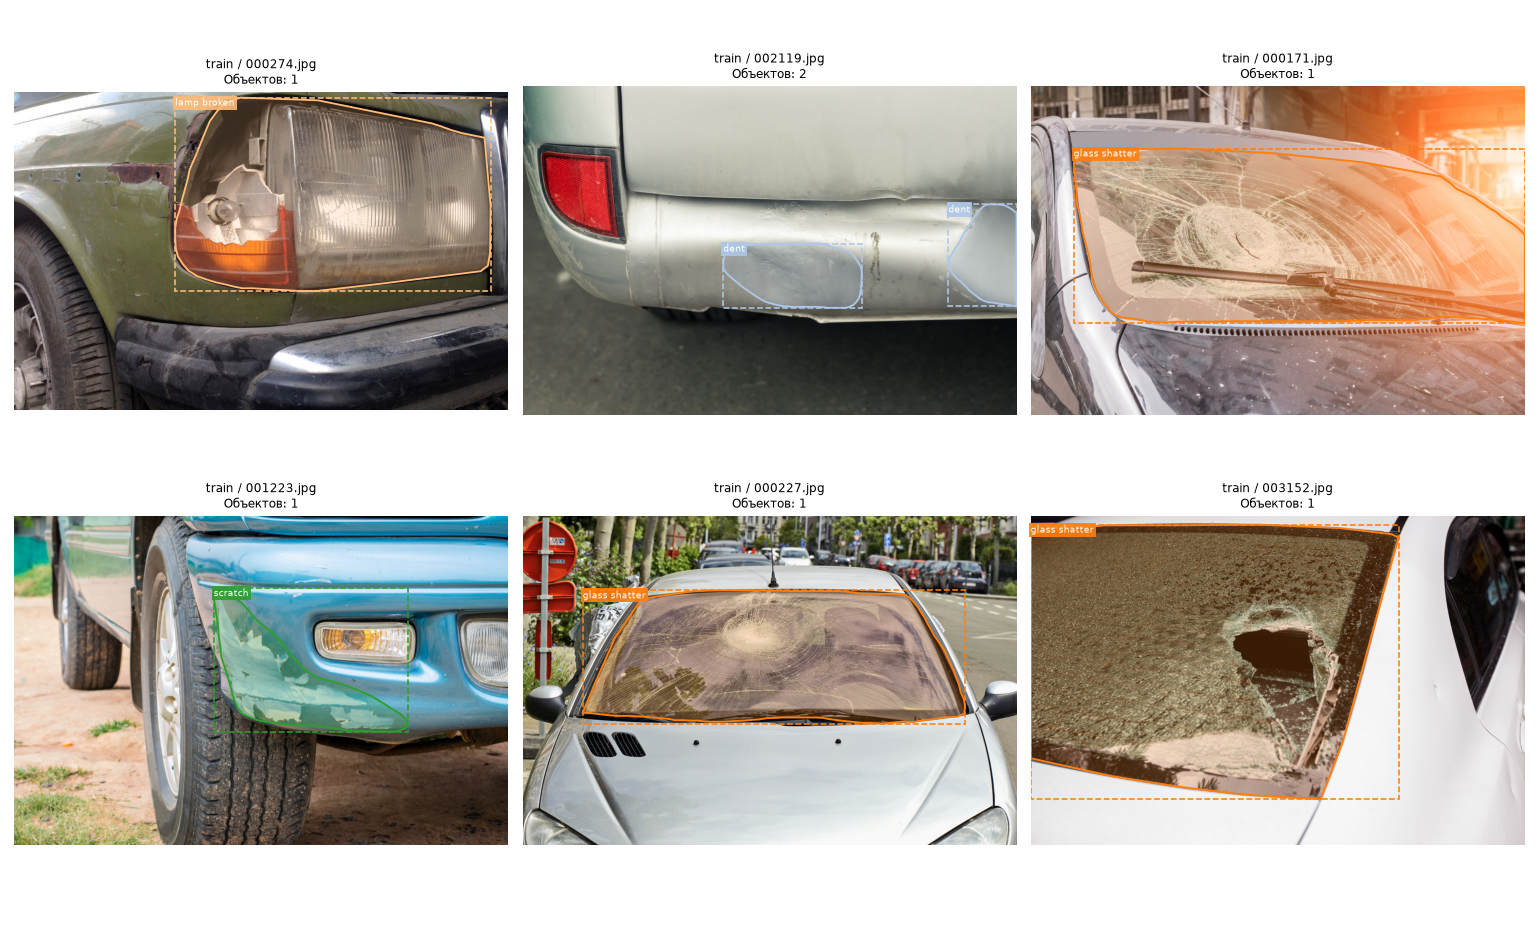

In [4]:
# Повторный запуск этой ячейки показывает новую случайную подборку.
figure, selected_samples = show_samples(
    dataset, n_images=N_IMAGES, n_cols=N_COLS, seed=SEED,
    split=SPLIT, class_filter=CLASS_FILTER,
    show_masks=SHOW_MASKS, show_boxes=SHOW_BOXES,
    show_labels=SHOW_LABELS, show_class_ids=SHOW_CLASS_IDS,
    only_annotated=ONLY_ANNOTATED,
)
